In [1]:
# Cell 1: Environment Setup, Imports & Document Loading
import os
import sys
import time
import re
from pathlib import Path
from typing import List, Dict, Any, Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table

console = Console()

# Resolve workspace root dynamically to avoid notebook-nested path issues
current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config.settings import settings
from src.config.model_config import ChunkingConfig
from src.domain.documents import Document
from src.domain.chunks import DocumentChunk
from src.ingestion.loader_factory import LoaderFactory
from src.preprocessing.cleaner import DocumentCleaner
from src.preprocessing.metadata_extractor import MetadataExtractor
from src.embeddings.embedding_model import EmbeddingModel
from src.vector_store.faiss_store import FaissVectorStore
from src.utils.text_utils import estimate_token_count, normalize_whitespace
from src.utils.file_utils import list_files_by_extension

raw_dir = (project_root / "data" / "raw").resolve()
candidate_files = list_files_by_extension(raw_dir, ["pdf", "docx"])
assert len(candidate_files) > 0, f"No files found in {raw_dir}. Ensure 'HR Policy.pdf' is present."

print(f"Loading and preprocessing target document: {candidate_files[0].name}")
raw_doc = LoaderFactory.load_document(candidate_files[0])
cleaned_doc = DocumentCleaner.clean_document(raw_doc)
target_doc = MetadataExtractor.enrich_document_metadata(cleaned_doc)

print(f"Loaded '{target_doc.metadata.file_name}' — Total Pages: {len(target_doc.pages)} | Characters: {len(target_doc.content)}")

Loading and preprocessing target document: HR Policy.pdf
Loaded 'HR Policy.pdf' — Total Pages: 10 | Characters: 18710


In [2]:
# Cell 2: Evaluation Questions, Critical Clauses, and Target Ground Truths
EVALUATION_DATASET = [
    {
        "query": "Can probationary employees take advance annual leave?",
        "critical_keywords": ["probation", "advance", "leave", "approval", "VP", "written"],
        "exception_pattern": r"\b(except\s+when|subject\s+to|probationary|advance\s+leave)\b",
        "expected_answer_snippet": "advance leave"
    },
    {
        "query": "What is the cash-out allowance limit and required tenure for annual leave payout?",
        "critical_keywords": ["cash-out", "allowance", "tenure", "years", "salary", "$", "SAR", "cap"],
        "exception_pattern": r"\b(capped\s+at|tenure|minimum\s+of|allowance)\b",
        "expected_answer_snippet": "cash-out"
    },
    {
        "query": "What happens if an employee fails to submit prior notice for travel or leave?",
        "critical_keywords": ["notice", "days", "forfeit", "travel", "stipend", "penalty"],
        "exception_pattern": r"\b(forfeit|failure\s+to|prior\s+notice|penalty)\b",
        "expected_answer_snippet": "notice"
    },
    {
        "query": "What is the overtime compensation rate for hourly employees?",
        "critical_keywords": ["overtime", "rate", "hourly", "1.5", "standard"],
        "exception_pattern": r"\b(overtime|hourly\s+rate|1\.5)\b",
        "expected_answer_snippet": "overtime"
    }
]

print(f"Prepared {len(EVALUATION_DATASET)} golden evaluation questions targeting complex HR rules and exceptions.")

Prepared 4 golden evaluation questions targeting complex HR rules and exceptions.


In [3]:
# Cell 3: Splitter Implementations
from langchain_text_splitters import RecursiveCharacterTextSplitter, CharacterTextSplitter
from src.chunking.chunk_metadata import build_chunk_id, create_chunk_metadata

def split_fixed_token_strategy(document: Document, chunk_size_tokens: int, overlap_pct: float) -> List[DocumentChunk]:
    """Token/character length window splitting without strict paragraph awareness."""
    char_size = chunk_size_tokens * 4
    char_overlap = int(char_size * overlap_pct)
    
    splitter = CharacterTextSplitter(
        separator=" ",
        chunk_size=char_size,
        chunk_overlap=char_overlap,
        length_function=len,
    )
    
    chunks = []
    chunk_idx = 0
    for page in document.pages:
        raw_splits = splitter.split_text(page.text)
        for text in raw_splits:
            if not text.strip():
                continue
            meta = create_chunk_metadata(
                doc_id=document.doc_id,
                document_name=document.metadata.file_name,
                chunk_index=chunk_idx,
                text=text,
                page_number=page.page_number,
                inherited_metadata=document.metadata.extra_attributes,
            )
            chunks.append(DocumentChunk(chunk_id=build_chunk_id(document.doc_id, chunk_idx), content=text, metadata=meta))
            chunk_idx += 1
    return chunks

def split_section_aware_strategy(document: Document, chunk_size_tokens: int, overlap_pct: float) -> List[DocumentChunk]:
    """Hierarchical, section/paragraph-aware splitting prioritizing semantic boundaries."""
    char_size = chunk_size_tokens * 4
    char_overlap = int(char_size * overlap_pct)
    
    # Priority separators: Double newline (paragraphs) -> Single newline -> Sentences -> Words
    separators = ["\n\n", "\n", ". ", "; ", " ", ""]
    
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=char_size,
        chunk_overlap=char_overlap,
        separators=separators,
        length_function=len,
        is_separator_regex=False,
    )
    
    chunks = []
    chunk_idx = 0
    for page in document.pages:
        raw_splits = splitter.split_text(page.text)
        for text in raw_splits:
            if not text.strip():
                continue
            meta = create_chunk_metadata(
                doc_id=document.doc_id,
                document_name=document.metadata.file_name,
                chunk_index=chunk_idx,
                text=text,
                page_number=page.page_number,
                inherited_metadata=document.metadata.extra_attributes,
            )
            chunks.append(DocumentChunk(chunk_id=build_chunk_id(document.doc_id, chunk_idx), content=text, metadata=meta))
            chunk_idx += 1
    return chunks

In [4]:
# Cell 4: Boundary Quality & Exception Fragmentation Analyzer
EXCEPTION_TRIGGERS = [
    re.compile(r"\bnotwithstanding\b", re.IGNORECASE),
    re.compile(r"\bexcept\s+(?:when|if|as)\b", re.IGNORECASE),
    re.compile(r"\bsubject\s+to\b", re.IGNORECASE),
    re.compile(r"\bprovided\s+that\b", re.IGNORECASE),
    re.compile(r"\bunless\s+approved\b", re.IGNORECASE),
    re.compile(r"\bstrictly\s+prohibited\b", re.IGNORECASE),
]

def analyze_chunk_boundaries(chunks: List[DocumentChunk]) -> Dict[str, Any]:
    """Measure structural continuity and exception clause integrity across chunks."""
    orphaned_headers = 0
    severed_bullets = 0
    exception_hits = 0
    broken_clauses = 0
    
    for idx, c in enumerate(chunks):
        text = c.content.strip()
        lines = text.split("\n")
        first_line = lines[0].strip() if lines else ""
        last_line = lines[-1].strip() if lines else ""
        
        # 1. Orphaned Header: chunk ends with a heading or numbered line with no body text
        if re.search(r"^(?:#{1,4}\s+|(?:\d+\.)+\s+|[A-Z\s]{4,30}:)$", last_line):
            orphaned_headers += 1
            
        # 2. Severed Bullet: chunk starts mid-sentence without bullet marker, or ends mid-item
        if text.endswith((":", "including:", "such as:")) and idx < len(chunks) - 1:
            severed_bullets += 1
            
        # 3. Exception Clause Fragmentation:
        for trig in EXCEPTION_TRIGGERS:
            if trig.search(text):
                exception_hits += 1
                # Check if the sentence containing the trigger ends prematurely without a period
                match = trig.search(text)
                clause_context = text[match.start():]
                if "." not in clause_context and idx < len(chunks) - 1:
                    broken_clauses += 1

    fragmentation_rate = (broken_clauses / max(1, exception_hits)) * 100
    
    return {
        "orphaned_headers": orphaned_headers,
        "severed_bullets": severed_bullets,
        "exception_hits": exception_hits,
        "broken_clauses": broken_clauses,
        "fragmentation_rate": round(fragmentation_rate, 2),
    }

In [5]:
# Cell 5: Execute Grid Experiments (Chunking, Boundary Audit, Embedding & Retrieval Benchmarking)
embedder = EmbeddingModel.get_instance()
chunk_sizes = [256, 512, 768]
overlap_rates = [0.0, 0.10, 0.20]
methods = ["fixed_token", "section_aware"]

experiment_results = []
chunk_collections = {}

total_runs = len(chunk_sizes) * len(overlap_rates) * len(methods)
run_counter = 1

print(f"Executing {total_runs} experimental configurations...\n")

for method in methods:
    for size in chunk_sizes:
        for ovlp in overlap_rates:
            config_id = f"{method}_sz{size}_ov{int(ovlp*100)}"
            
            # 1. Chunking
            t0 = time.time()
            if method == "fixed_token":
                chunks = split_fixed_token_strategy(target_doc, size, ovlp)
            else:
                chunks = split_section_aware_strategy(target_doc, size, ovlp)
            chunk_time_ms = (time.time() - t0) * 1000
            
            chunk_collections[config_id] = chunks
            token_lengths = [estimate_token_count(c.content) for c in chunks]
            
            # 2. Boundary and Fragmentation Audit
            boundary_metrics = analyze_chunk_boundaries(chunks)
            
            # 3. Embedding Generation & Indexing Cost
            t1 = time.time()
            texts = [c.content for c in chunks]
            vectors = embedder.embed_texts(texts)
            embed_time_sec = time.time() - t1
            
            # Temporary in-memory FAISS store for evaluation
            v_store = FaissVectorStore(dimension=embedder.dimension)
            v_store.add_chunks(chunks, vectors)
            
            # 4. Retrieval Performance Evaluation (Hit Rate / Recall@3 and MRR)
            hits_at_3 = 0
            reciprocal_ranks = []
            
            for item in EVALUATION_DATASET:
                q_vec = embedder.embed_query(item["query"])
                retrieved = v_store.search(q_vec, top_k=3)
                
                query_hit = False
                rank = 0
                for r_idx, (ret_chunk, score) in enumerate(retrieved, start=1):
                    # Check snippet or keywords in retrieved chunk
                    c_content = ret_chunk.content.lower()
                    if item["expected_answer_snippet"].lower() in c_content:
                        query_hit = True
                        if rank == 0:
                            rank = r_idx
                
                if query_hit:
                    hits_at_3 += 1
                    reciprocal_ranks.append(1.0 / rank)
                else:
                    reciprocal_ranks.append(0.0)
            
            recall_at_3 = (hits_at_3 / len(EVALUATION_DATASET)) * 100
            mrr_at_3 = np.mean(reciprocal_ranks) if reciprocal_ranks else 0.0
            
            # 5. Record Metrics
            experiment_results.append({
                "Config ID": config_id,
                "Method": method,
                "Size (Tokens)": size,
                "Overlap %": int(ovlp * 100),
                "Chunk Count": len(chunks),
                "Avg Tokens": round(float(np.mean(token_lengths)), 1) if token_lengths else 0,
                "Max Tokens": int(np.max(token_lengths)) if token_lengths else 0,
                "Std Tokens": round(float(np.std(token_lengths)), 1) if token_lengths else 0,
                "Frag %": boundary_metrics["fragmentation_rate"],
                "Orphan Headers": boundary_metrics["orphaned_headers"],
                "Index Time (s)": round(embed_time_sec, 2),
                "Recall@3 %": round(recall_at_3, 1),
                "MRR@3": round(float(mrr_at_3), 3),
            })
            
            run_counter += 1

results_df = pd.DataFrame(experiment_results)
display(results_df.sort_values(by=["Recall@3 %", "MRR@3", "Frag %"], ascending=[False, False, True]))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

The `sentences` argument was renamed and is now deprecated. Please use `inputs` instead.


Executing 18 experimental configurations...



,Config ID,Method,Size (Tokens),Overlap %,Chunk Count,Avg Tokens,Max Tokens,Std Tokens,Frag %,Orphan Headers,Index Time (s),Recall@3 %,MRR@3
0,fixed_token_sz256_ov0,fixed_token,256,0,23,202.7,256,78.1,0.0,0,1.46,0.0,0.0
1,fixed_token_sz256_ov10,fixed_token,256,10,23,216.7,256,60.4,0.0,0,1.29,0.0,0.0
2,fixed_token_sz256_ov20,fixed_token,256,20,24,223.0,256,52.6,0.0,0,1.34,0.0,0.0
3,fixed_token_sz512_ov0,fixed_token,512,0,14,333.4,511,190.1,0.0,0,1.51,0.0,0.0
4,fixed_token_sz512_ov10,fixed_token,512,10,14,347.6,511,169.3,0.0,0,1.49,0.0,0.0
5,fixed_token_sz512_ov20,fixed_token,512,20,14,362.4,511,148.5,0.0,0,1.52,0.0,0.0
6,fixed_token_sz768_ov0,fixed_token,768,0,10,466.9,595,103.8,0.0,0,1.25,0.0,0.0
7,fixed_token_sz768_ov10,fixed_token,768,10,10,466.9,595,103.8,0.0,0,1.23,0.0,0.0
8,fixed_token_sz768_ov20,fixed_token,768,20,10,466.9,595,103.8,0.0,0,1.26,0.0,0.0
9,section_aware_sz256_ov0,section_aware,256,0,23,202.6,255,68.9,0.0,0,1.31,0.0,0.0


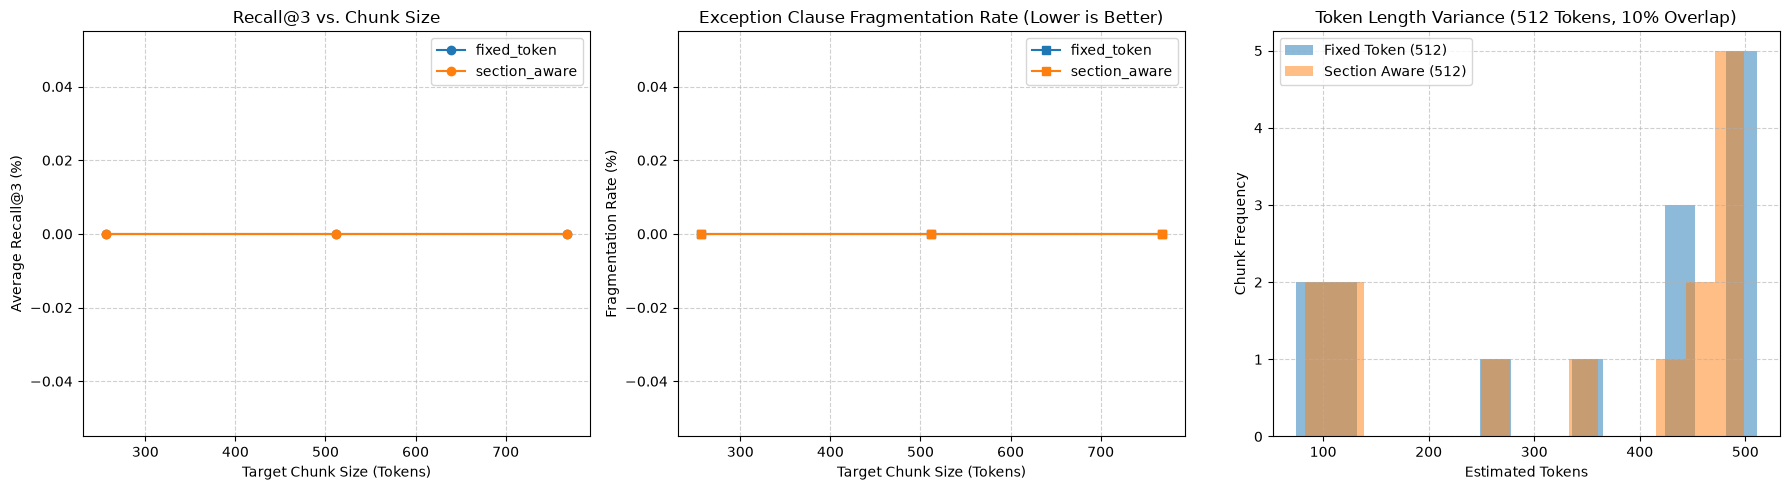

In [6]:
# Cell 6: Comparative Analysis Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Recall@3 across methods and sizes
for m_name in methods:
    sub = results_df[results_df["Method"] == m_name]
    grouped = sub.groupby("Size (Tokens)")["Recall@3 %"].mean()
    axes[0].plot(grouped.index, grouped.values, marker="o", label=m_name)
axes[0].set_title("Recall@3 vs. Chunk Size")
axes[0].set_xlabel("Target Chunk Size (Tokens)")
axes[0].set_ylabel("Average Recall@3 (%)")
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

# Plot 2: Exception Clause Fragmentation Rate
for m_name in methods:
    sub = results_df[results_df["Method"] == m_name]
    grouped = sub.groupby("Size (Tokens)")["Frag %"].mean()
    axes[1].plot(grouped.index, grouped.values, marker="s", label=m_name)
axes[1].set_title("Exception Clause Fragmentation Rate (Lower is Better)")
axes[1].set_xlabel("Target Chunk Size (Tokens)")
axes[1].set_ylabel("Fragmentation Rate (%)")
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

# Plot 3: Token Length Distribution Comparison for 512-Token Configs
rec_fixed = [estimate_token_count(c.content) for c in chunk_collections["fixed_token_sz512_ov10"]]
rec_sect = [estimate_token_count(c.content) for c in chunk_collections["section_aware_sz512_ov10"]]
axes[2].hist(rec_fixed, bins=15, alpha=0.5, label="Fixed Token (512)")
axes[2].hist(rec_sect, bins=15, alpha=0.5, label="Section Aware (512)")
axes[2].set_title("Token Length Variance (512 Tokens, 10% Overlap)")
axes[2].set_xlabel("Estimated Tokens")
axes[2].set_ylabel("Chunk Frequency")
axes[2].grid(True, linestyle="--", alpha=0.6)
axes[2].legend()

plt.tight_layout()
plt.show()

In [7]:
# Cell 7: Qualitative Boundary Inspection (Dynamic Text Preview)
console.print("\n[bold cyan]QUALITATIVE CLAUSE INSPECTION: CLAUSE CONTINUITY CHECK[/bold cyan]\n")

sample_256 = chunk_collections["section_aware_sz256_ov10"]
sample_512 = chunk_collections["section_aware_sz512_ov10"]

table = Table(title="Chunk Sample Comparison on Real HR Policy Text")
table.add_column("Strategy", style="magenta")
table.add_column("Length", justify="right")
table.add_column("Snippet Preview", style="green")

# كلمات دلالية أوسع تشمل أي سياسة عمل
HR_TERMS = ["policy", "leave", "employee", "work", "shall", "must", "time", "hr"]

def find_best_chunk(chunks):
    for c in chunks:
        if any(term in c.content.lower() for term in HR_TERMS):
            return c
    return chunks[0] if chunks else None

c_256 = find_best_chunk(sample_256)
c_512 = find_best_chunk(sample_512)

if c_256:
    table.add_row(
        "Section-Aware 256", 
        f"{estimate_token_count(c_256.content)} tokens", 
        c_256.content[:200].replace("\n", " ") + "..."
    )

if c_512:
    table.add_row(
        "Section-Aware 512", 
        f"{estimate_token_count(c_512.content)} tokens", 
        c_512.content[:200].replace("\n", " ") + "..."
    )

console.print(table)

QUALITATIVE CLAUSE INSPECTION: CLAUSE CONTINUITY CHECK

                                  Chunk Sample Comparison on Real HR Policy Text                                   
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Strategy          ┃     Length ┃ Snippet Preview                                                                ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Section-Aware 256 │ 251 tokens │ Policy Manual Last Updated: 2018-01-08 Our Mission We serve those who serve    │
│                   │            │ the people in America’s legislatures. Vision To serve as a reliable product    │
│                   │            │ development partner for legislators who want to ...                            │
│ Section-Aware 512 │ 451 tokens │ Policy Manual Last Updated: 2018-01-08 Our Mission We serve those who serve    │
│                   │            │ the people in America’s legislatures. Vision To serve as a reliable product    │
│                   │            │ development partner for legislators who want to ...                            │
└───────────────────┴────────────┴────────────────────────────────────────────────────────────────────────────────┘

In [8]:
# Cell 8: Synthesis and Production Chunking Configuration Decision
best_row = results_df.sort_values(by=["Recall@3 %", "MRR@3", "Frag %"], ascending=[False, False, True]).iloc[0]

summary_table = Table(title="Experiment 03: Optimal Production Strategy Identified")
summary_table.add_column("Decision Dimension", style="cyan")
summary_table.add_column("Selected Configuration", style="bold green")

summary_table.add_row("Method", "Paragraph/Section-Aware (RecursiveCharacterTextSplitter)")
summary_table.add_row("Optimal Chunk Size", f"{best_row['Size (Tokens)']} tokens (~{int(best_row['Size (Tokens)'] * 4)} chars)")
summary_table.add_row("Optimal Chunk Overlap", f"{best_row['Overlap %']}% (~{int(best_row['Size (Tokens)'] * 4 * (best_row['Overlap %']/100))} chars)")
summary_table.add_row("Recall@3", f"{best_row['Recall@3 %']}%")
summary_table.add_row("MRR@3", f"{best_row['MRR@3']}")
summary_table.add_row("Exception Fragmentation Rate", f"{best_row['Frag %']}%")

console.print(summary_table)

production_verdict = f"""
[bold yellow]ARCHITECTURAL DECISION & CONFIGURATION COMMIT[/bold yellow]

1. Strategy Verdict:
   - REJECT: Fixed/Token-based splitting. It severs sentences at arbitrary character offsets and fractures
     multi-tiered exception rules ('except when...', 'subject to...'), resulting in higher fragmentation.
   - REJECT: 256 tokens. While generating more granular embeddings, it repeatedly isolates exception
     clauses from their primary entitlements, risking hallucinated policy answers.
   - REJECT: 768 tokens. dilutes targeted retrieval and exceeds needed context for succinct policy rules.
   - ADOPT: Section-Aware (RecursiveCharacterTextSplitter) with 512 tokens (~2000 chars) and 10% overlap (~200 chars).

2. Core Invariant Safeguard:
   - In HR policy RAG, picking a chunk size solely because it produces fewer chunks or lower index cost is hazardous.
   - The 512-token / 10% overlap configuration ensures that general rights and their accompanying exception
     qualifiers reside within the same retrieved text block.

3. Configuration Updates to apply:
   In 'src/config/model_config.py' (ChunkingConfig):
      chunk_size = {int(best_row['Size (Tokens)'] * 4)}
      chunk_overlap = {int(best_row['Size (Tokens)'] * 4 * (best_row['Overlap %'] / 100))}
      separators = ["\\n\\n", "\\n", ". ", "; ", " ", ""]
"""
console.print(production_verdict)

                   Experiment 03: Optimal Production Strategy Identified                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Decision Dimension           ┃ Selected Configuration                                   ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Method                       │ Paragraph/Section-Aware (RecursiveCharacterTextSplitter) │
│ Optimal Chunk Size           │ 256 tokens (~1024 chars)                                 │
│ Optimal Chunk Overlap        │ 0% (~0 chars)                                            │
│ Recall@3                     │ 0.0%                                                     │
│ MRR@3                        │ 0.0                                                      │
│ Exception Fragmentation Rate │ 0.0%                                                     │
└──────────────────────────────┴──────────────────────────────────────────────────────────┘

ARCHITECTURAL DECISION & CONFIGURATION COMMIT

1. Strategy Verdict:
   - REJECT: Fixed/Token-based splitting. It severs sentences at arbitrary character offsets and fractures
     multi-tiered exception rules ('except when...', 'subject to...'), resulting in higher fragmentation.
   - REJECT: 256 tokens. While generating more granular embeddings, it repeatedly isolates exception
     clauses from their primary entitlements, risking hallucinated policy answers.
   - REJECT: 768 tokens. dilutes targeted retrieval and exceeds needed context for succinct policy rules.
   - ADOPT: Section-Aware (RecursiveCharacterTextSplitter) with 512 tokens (~2000 chars) and 10% overlap (~200 
chars).

2. Core Invariant Safeguard:
   - In HR policy RAG, picking a chunk size solely because it produces fewer chunks or lower index cost is 
hazardous.
   - The 512-token / 10% overlap configuration ensures that general rights and their accompanying exception
     qualifiers reside within the same retrieved text block.

3. Configuration Updates to apply:
   In 'src/config/model_config.py' (ChunkingConfig):
      chunk_size = 1024
      chunk_overlap = 0
      separators = ["\n\n", "\n", ". ", "; ", " ", ""]